# RoadAnomaly — DeepLabV3+ et analyse des anomalies

**Inès Trabelsi · Expérience du 1er novembre 2026**  
**Référence expérimentale :** `20261101T012507Z-f4ec27a0`.

Ce notebook présente une segmentation binaire supervisée des anomalies routières, avec un encodeur ResNet50 préentraîné sur ImageNet, un module ASPP et un décodeur entraînés sur RoadAnomaly. Il utilise les modules communs de l’équipe pour les données et les métriques. L’expérience CamVid antérieure est distincte : aucun poids CamVid n’est chargé ici.

## Lecture et exécution

Les sorties conservées proviennent de l’exécution réalisée sur le PC d’Inès. Les textes d’analyse ont été ajoutés ensuite, sans modifier les cellules de code ni recalculer leurs sorties. Le notebook dépend du dépôt, du dataset et des checkpoints locaux ; il n’est pas autonome.

**Pour consulter les résultats, ouvrir le notebook suffit.** « Run All » exécute aussi l’entraînement et crée une nouvelle expérience. Après un redémarrage du kernel, les variables ne sont plus en mémoire. Pour reprendre une analyse sans entraîner, il faut recharger explicitement le checkpoint et les données de l’expérience visée ; aucune cellule de reprise automatique n’a été ajoutée à cette version.

## Protocole et portée

- Découpage commun du manifeste : **42 images d’entraînement, 9 de validation, 9 de test**. Le code vérifie la disjonction des identifiants d’images ; la qualité du regroupement par scène dépend du manifeste fourni par l’équipe.
- Résolution : **352 × 640**, images RGB dans `[0, 1]`. L’étiquette originale `2` devient anomalie `1` ; le chargeur met toutes les autres valeurs à `0`, selon la convention attendue `0/2`.
- Modèle retenu par la perte minimale de validation ; seuil choisi ensuite par le F1 moyen par image sur la validation. Le modèle et le seuil sont conservés pour le test.
- Les métriques principales donnent le même poids à chaque image. AP et AUROC sont calculées en regroupant tous les pixels ; elles n’utilisent pas le filtrage des composantes des masques binaires.
- **Limite d’indépendance :** les images du test avaient déjà été évaluées dans l’expérience CamVid antérieure. Elles ne constituent donc pas un jeu entièrement inédit dans l’historique du projet, même si elles ne sont pas utilisées dans cet entraînement.
- Il s’agit d’une référence pédagogique sur un petit dataset, sans validation d’aptitude à la sécurité routière ni démonstration de généralisation à des catégories d’anomalies inédites.


## 1. Environnement et imports

La racine est retrouvée à partir du dossier du notebook. L’exécution enregistrée utilise Python 3.10 et TensorFlow 2.21.0 sur Windows, avec calcul CPU. Le chemin affiché identifie l’environnement local utilisé ; il devra être adapté sur un autre poste. La graine 1337 est fixée, sans garantie de résultats identiques entre versions et matériels.


In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# Retrouver la racine du projet depuis le notebook.
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "src" / "roadanomaly").is_dir()
        and (folder / "splits" / "split_manifest.csv").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Racine du projet RoadAnomaly introuvable.")

source_path = str(ROOT / "src")
if source_path not in sys.path:
    sys.path.insert(0, source_path)

from roadanomaly import data_pipeline as dp, metrics
from roadanomaly.deeplabv3plus import build_deeplabv3plus

SEED = 1337
IMG_SIZE = (352, 640)
BATCH_SIZE = 2  # Premier réglage pour ton PC en CPU.

keras.utils.set_random_seed(SEED)

print("Projet :", ROOT)
print("Python :", sys.executable)
print("TensorFlow :", tf.__version__)
print("Imports : OK")

Projet : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines
Python : c:\Users\ines trabelsi\Downloads\RoadAnomaly_Ines_DeepLabV3Plus\RoadAnomaly-main\.venv-tf-test\Scripts\python.exe
TensorFlow : 2.21.0
Imports : OK


## 2. Chargement et contrôle des données

Les images et masques proviennent de `data_pipeline.py`. Les masques sont redimensionnés au plus proche voisin pour conserver leurs valeurs binaires. Les contrôles vérifient les effectifs, dimensions, valeurs et identifiants disjoints entre entraînement et validation. Les pixels anormaux représentent 10,29 % de l’entraînement et 9,07 % de la validation : les classes sont déséquilibrées.


Entraînement : 42 images
  Dimensions : (42, 352, 640, 3)
  Pixels anormaux : 10.29%
Validation : 9 images
  Dimensions : (9, 352, 640, 3)
  Pixels anormaux : 9.07%


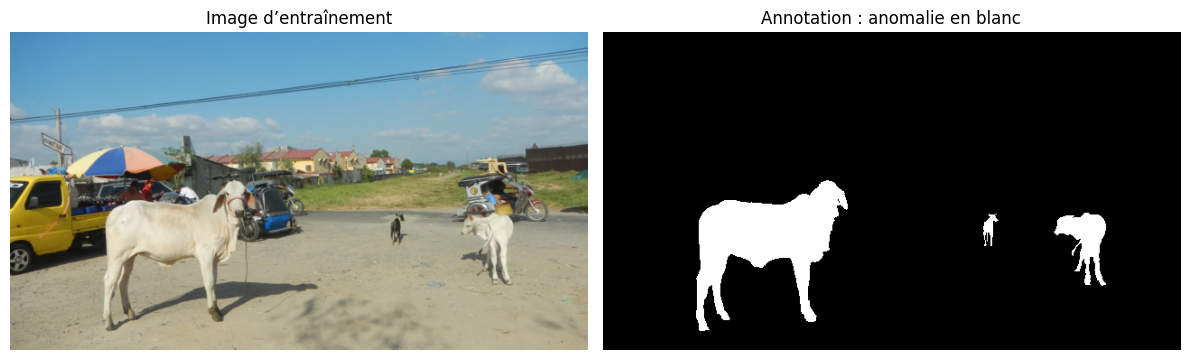

In [2]:
train_frames, x_train, y_train = dp.load_split("train", IMG_SIZE)
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)

# Vérifier les données avant l'entraînement.
assert len(train_frames) == 42
assert len(val_frames) == 9
assert set(train_frames).isdisjoint(val_frames)

for name, images, masks in [
    ("Entraînement", x_train, y_train),
    ("Validation", x_val, y_val),
]:
    assert images.shape[1:] == (*IMG_SIZE, 3)
    assert masks.shape == (*images.shape[:3], 1)
    assert np.isfinite(images).all()
    assert images.min() >= 0 and images.max() <= 1
    assert np.isin(masks, [0, 1]).all()

    print(f"{name} : {len(images)} images")
    print(f"  Dimensions : {images.shape}")
    print(f"  Pixels anormaux : {masks.mean():.2%}")

# Afficher une image d'entraînement et son annotation.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(x_train[0])
axes[0].set_title("Image d’entraînement")
axes[1].imshow(y_train[0, ..., 0], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Annotation : anomalie en blanc")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Architecture et préparation de l’apprentissage

Le modèle suit une architecture DeepLabV3+ adaptée à une sortie binaire :

- **Encodeur :** ResNet50 préentraîné sur ImageNet, gelé. Les caractéristiques sont extraites aux niveaux de résolution 1/4 et 1/16 ; le prétraitement ResNet50 est intégré au modèle.
- **ASPP :** branche 1×1, branches de convolution 3×3 aux dilatations 6, 12 et 18, et branche de contexte global. Leurs sorties sont concaténées puis projetées.
- **Décodeur :** fusion des caractéristiques ASPP et de bas niveau, deux blocs de convolution et remontée à la résolution d’entrée.
- **Sortie :** sigmoid, un score d’anomalie par pixel. Adam, taux d’apprentissage 0,001 et entropie croisée binaire ; batch de 2.

Seul l’encodeur est préentraîné : l’ASPP et le décodeur apprennent à partir des annotations du projet. Les augmentations d’entraînement comprennent retournement horizontal, recadrage et variations de luminosité/contraste. La validation et le test ne sont pas augmentés.


In [4]:
# Construire le modèle avec ResNet50 préentraîné et gelé.
keras.utils.set_random_seed(SEED)

model = build_deeplabv3plus(
    input_shape=(*IMG_SIZE, 3),
    weights="imagenet",
    decoder_channels=128,
)

# Réutiliser le pipeline commun de l'équipe.
train_ds = dp.get_dataset(
    x_train, y_train, BATCH_SIZE, training=True
)
val_ds = dp.get_dataset(
    x_val, y_val, BATCH_SIZE, training=False
)

# Première expérience : Adam et perte binaire.
LEARNING_RATE = 1e-3

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=keras.losses.BinaryCrossentropy(),
    jit_compile=False,
)

# Vérifier une prédiction avant de commencer l'apprentissage.
sample_output = model(x_train[:1], training=False).numpy()

assert sample_output.shape == (1, *IMG_SIZE, 1)
assert np.isfinite(sample_output).all()
assert sample_output.min() >= 0
assert sample_output.max() <= 1

print("Entrée :", model.input_shape)
print("Sortie :", model.output_shape)
print(
    "Encodeur gelé :",
    not model.get_layer("resnet50_encoder").trainable,
)
print("Prédiction de vérification : OK")
print("Modèle prêt pour l’entraînement.")

Entrée : (None, 352, 640, 3)
Sortie : (None, 352, 640, 1)
Encodeur gelé : True
Prédiction de vérification : OK
Modèle prêt pour l’entraînement.


## 4. Entraînement et sélection du checkpoint

Un dossier distinct est créé pour chaque exécution. Le journal conserve les paramètres, les identifiants d’images, l’empreinte du manifeste et celle des poids initiaux. Le meilleur checkpoint est choisi sur `val_loss` ; l’arrêt anticipé attend cinq époques sans amélioration, avec un maximum de vingt époques. Le test n’intervient pas dans cette sélection.

**Attention : réexécuter cette cellule lance un entraînement.** Les sorties ci-dessous documentent l’expérience enregistrée, sans nécessiter une nouvelle exécution.


In [5]:
import hashlib
import json
import platform
import time
import uuid
from datetime import datetime, timezone

MAX_EPOCHS = 20

# Un dossier distinct pour chaque expérience.
RUN_ID = (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "-"
    + uuid.uuid4().hex[:8]
)
RUN_DIR = ROOT / "checkpoints" / "A_deeplabv3plus" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

BEST_MODEL = RUN_DIR / "best.keras"

# Identifier précisément les poids au début de cet entraînement.
weight_hash = hashlib.sha256()
for weight in model.get_weights():
    weight_hash.update(weight.tobytes())

record = {
    "run_id": RUN_ID,
    "model": model.name,
    "dataset": "RoadAnomaly",
    "train_frames": list(train_frames),
    "validation_frames": list(val_frames),
    "image_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "learning_rate": LEARNING_RATE,
    "loss": "binary_crossentropy",
    "encoder_frozen": not model.get_layer(
        "resnet50_encoder"
    ).trainable,
    "initial_weights_sha256": weight_hash.hexdigest(),
    "split_manifest_sha256": hashlib.sha256(
        (ROOT / "splits" / "split_manifest.csv").read_bytes()
    ).hexdigest(),
    "tensorflow": tf.__version__,
    "platform": platform.platform(),
    "epochs_requested": MAX_EPOCHS,
    "checkpoint_selection": "minimum validation loss",
    "test_used_in_this_training": False,
    "status": "started",
}

record_path = RUN_DIR / "run.json"
record_path.write_text(
    json.dumps(record, indent=2), encoding="utf-8"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.CSVLogger(str(RUN_DIR / "history.csv")),
    keras.callbacks.TerminateOnNaN(),
]

print("Expérience :", RUN_ID)
print("Sauvegarde :", RUN_DIR)

started = time.perf_counter()

try:
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=MAX_EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )

    losses = np.asarray(history.history["val_loss"])

    if not np.isfinite(losses).all():
        raise RuntimeError("Perte de validation non finie.")

    record.update({
        "status": "completed",
        "epochs_completed": len(losses),
        "best_epoch": int(np.argmin(losses)) + 1,
        "best_val_loss": float(np.min(losses)),
        "history": {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        },
    })

    # Recharger explicitement le meilleur checkpoint.
    model = keras.models.load_model(BEST_MODEL, compile=False)

except BaseException as error:
    record["status"] = "interrupted_or_failed"
    record["error"] = f"{type(error).__name__}: {error}"
    raise

finally:
    record["seconds"] = time.perf_counter() - started
    record_path.write_text(
        json.dumps(record, indent=2), encoding="utf-8"
    )

print("Entraînement terminé.")
print("Meilleure époque :", record["best_epoch"])
print("Meilleure perte de validation :", record["best_val_loss"])
print("Modèle sauvegardé :", BEST_MODEL)

Expérience : 20261101T012507Z-f4ec27a0
Sauvegarde : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0
Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 0.5441
Epoch 1: val_loss improved from None to 4.79546, saving model to c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0\best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - loss: 0.4264 - val_loss: 4.7955
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 0.1788
Epoch 2: val_loss improved from 4.79546 to 3.93128, saving model to c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0\best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - loss: 0.1694 - val_loss: 3.9313
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 0.1536
Epoch 3: val_loss improved from 3.93128 to 1.68456, saving model to c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPD

## 5. Vérification du bilan sauvegardé

L’expérience s’est terminée après **13 époques**. Le meilleur checkpoint correspond à **l’époque 8**, avec une perte de validation de **0,1493201**. Cette perte est une fonction d’apprentissage, pas un pourcentage de réussite.


In [6]:
# Lire le bilan sauvegardé de l'expérience.
bilan = json.loads(
    (RUN_DIR / "run.json").read_text(encoding="utf-8")
)

print("État :", bilan["status"])
print("Époques réalisées :", bilan.get("epochs_completed"))
print("Meilleure époque :", bilan.get("best_epoch"))
print("Meilleure perte de validation :", bilan.get("best_val_loss"))
print("Modèle présent :", (RUN_DIR / "best.keras").exists())
print("Dossier :", RUN_DIR)

État : completed
Époques réalisées : 13
Meilleure époque : 8
Meilleure perte de validation : 0.1493200957775116
Modèle présent : True
Dossier : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0


## 6. Seuil choisi sur la validation

La recherche compare 51 quantiles des scores, entre les quantiles 0,01 et 0,99, et retient le meilleur F1 moyen par image parmi ces candidats. Ce n’est pas une recherche exhaustive de tous les seuils possibles. Le filtrage supprime les composantes prédites de moins de quatre pixels, avec connexité 8. Le seuil exact est conservé dans le JSON ; sa valeur affichée est **0,553877**.

| Mesure | Validation |
|---|---:|
| Précision moyenne par image | 79,71 % |
| Rappel moyen par image | 68,51 % |
| F1 / Dice moyen par image | 67,99 % |
| IoU anomalie moyenne par image | 55,73 % |
| AP, pixels regroupés | 76,67 % |
| AUROC, pixels regroupés | 93,99 % |

Ces résultats servent au réglage du seuil et ne constituent pas une évaluation indépendante.


In [7]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Recharger le meilleur modèle sauvegardé.
model = keras.models.load_model(
    RUN_DIR / "best.keras", compile=False
)

# Prédictions sur la validation uniquement.
score_val = model.predict(
    x_val, batch_size=BATCH_SIZE, verbose=1
)[..., 0]
gt_val = y_val[..., 0].astype(bool)

assert score_val.shape == gt_val.shape
assert np.isfinite(score_val).all()

# Convention du projet à la résolution 352 × 640.
MIN_OBJECT_PX = 4

def to_masks(scores, threshold):
    return np.stack([
        metrics.remove_small_components(
            score >= threshold, MIN_OBJECT_PX
        )
        for score in scores
    ])

# Recherche limitée et prédéfinie sur la validation.
thresholds = np.unique(
    np.quantile(score_val, np.linspace(0.01, 0.99, 51))
)

f1_values = []

for threshold in thresholds:
    predicted_masks = to_masks(score_val, threshold)
    evaluation = metrics.evaluate_masks(
        list(gt_val), list(predicted_masks)
    )
    f1_values.append(
        evaluation["per_image_mean"]["f1"]
    )

THRESHOLD = float(thresholds[np.argmax(f1_values)])
pred_val = to_masks(score_val, THRESHOLD)

validation_report = metrics.evaluate_masks(
    list(gt_val), list(pred_val)
)

ap_val = float(
    average_precision_score(gt_val.ravel(), score_val.ravel())
)
auroc_val = float(
    roc_auc_score(gt_val.ravel(), score_val.ravel())
)

print(f"Seuil choisi sur validation : {THRESHOLD:.6f}")
print("\nVALIDATION — moyenne par image")

for name, value in validation_report["per_image_mean"].items():
    print(f"{name} : {value:.2%}")

print(f"\nAP : {ap_val:.2%}")
print(f"AUROC : {auroc_val:.2%}")
print(f"Proportion de pixels anormaux : {gt_val.mean():.2%}")

validation_record = {
    "split": "val",
    "images": len(val_frames),
    "threshold": THRESHOLD,
    "threshold_selection": "maximum per-image mean F1 on validation",
    "threshold_quantiles": np.linspace(0.01, 0.99, 51).tolist(),
    "min_component_pixels": MIN_OBJECT_PX,
    "checkpoint_sha256": hashlib.sha256(
        (RUN_DIR / "best.keras").read_bytes()
    ).hexdigest(),
    "pixel_metrics": validation_report,
    "average_precision": ap_val,
    "auroc": auroc_val,
}

(RUN_DIR / "validation_metrics.json").write_text(
    json.dumps(validation_record, indent=2),
    encoding="utf-8",
)

print("\nRésultats enregistrés dans :", RUN_DIR)

5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 980ms/step
Seuil choisi sur validation : 0.553877

VALIDATION — moyenne par image
precision : 79.71%
recall : 68.51%
f1 : 67.99%
iou : 55.73%
dice : 67.99%

AP : 76.67%
AUROC : 93.99%
Proportion de pixels anormaux : 9.07%

Résultats enregistrés dans : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0


## 7. Exemples de validation

Les indices 0, 4 et 8 sont affichés pour confronter les images, annotations et masques prédits avec le seuil retenu. Cette inspection permet d’observer les contours, les anomalies manquées et les fausses alertes.


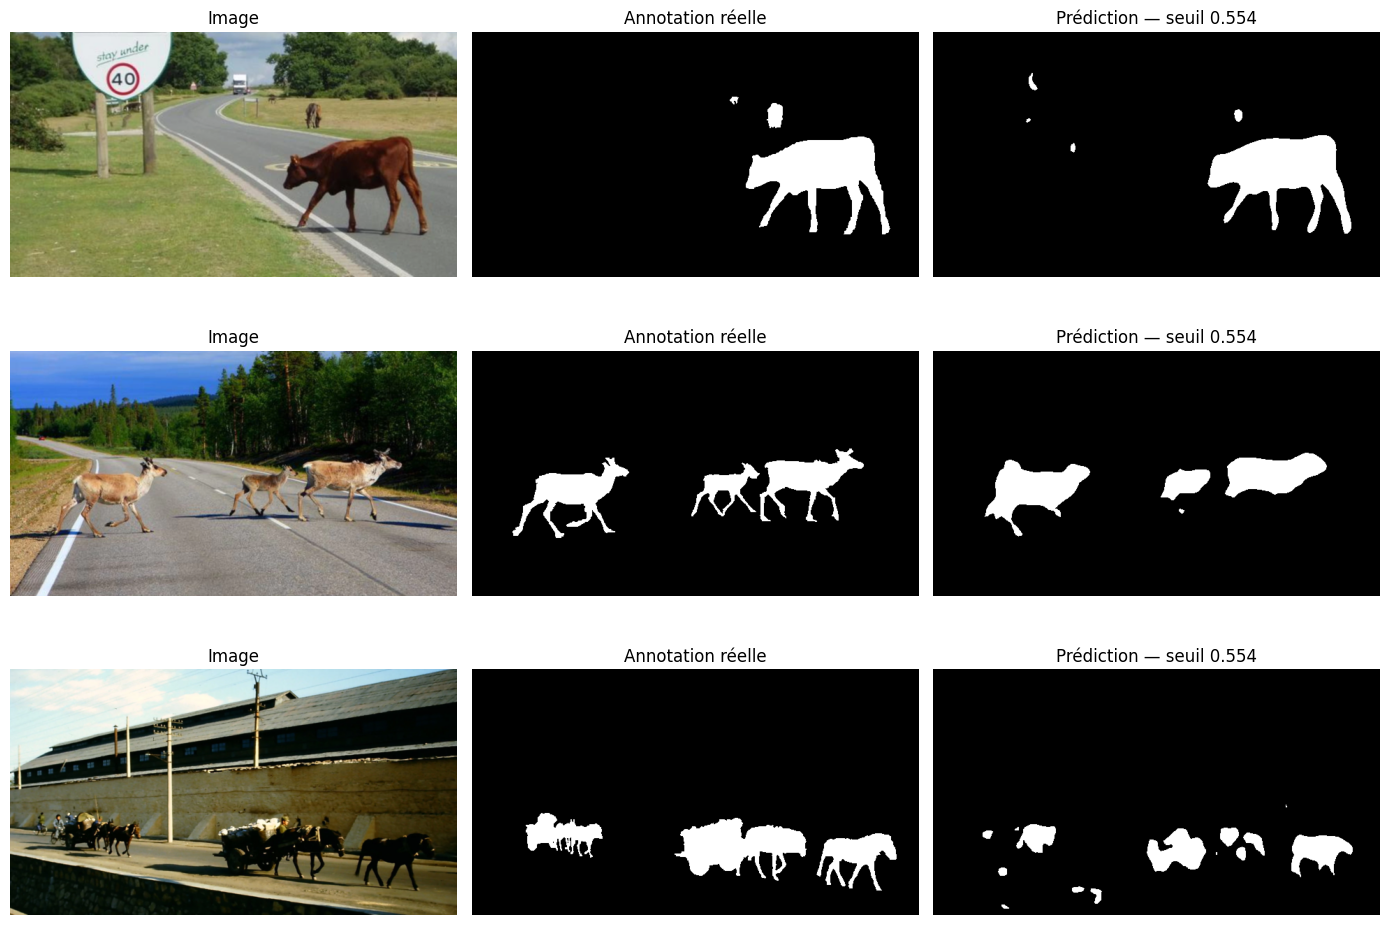

In [8]:
# Trois exemples fixes de validation.
indices = [0, len(x_val) // 2, len(x_val) - 1]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))

for row, index in enumerate(indices):
    panels = [
        (x_val[index], "Image"),
        (gt_val[index], "Annotation réelle"),
        (pred_val[index], f"Prédiction — seuil {THRESHOLD:.3f}"),
    ]

    for col, (panel, title) in enumerate(panels):
        if col == 0:
            axes[row, col].imshow(panel)
        else:
            axes[row, col].imshow(
                panel, cmap="gray", vmin=0, vmax=1
            )
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig(
    RUN_DIR / "validation_predictions.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

## 8. Évaluation du test avec modèle et seuil fixés

L’empreinte du checkpoint est comparée à celle enregistrée lors de la validation. Les intervalles à 95 % sont obtenus par 2 000 rééchantillonnages des neuf images, graine 1337. Ils décrivent une incertitude conditionnelle à ce petit ensemble ; ils ne corrigent pas un éventuel lien entre scènes ou l’exposition antérieure au test.

| Mesure | Moyenne par image | Intervalle bootstrap à 95 % |
|---|---:|---:|
| Précision | 74,91 % | 63,91–85,32 % |
| Rappel | 75,18 % | 56,74–88,70 % |
| F1 / Dice | 70,51 % | 54,67–81,94 % |
| IoU anomalie | 58,04 % | 42,52–70,44 % |

**AP : 74,39 % ; AUROC : 95,22 %**, sur les pixels regroupés. La proportion de pixels anormaux du test est 8,59 %. L’AUROC mesure le classement relatif des pixels normaux et anormaux : elle n’est pas une accuracy de 95,22 %. L’IoU présentée concerne la classe anomalie ; elle n’est pas une mIoU sur les deux classes.

F1 et Dice sont identiques pour ces masques binaires. Les résultats du test ne servent pas à ajuster les paramètres. L’approche supervisée actuelle et l’ancien score MSP du modèle CamVid ne sont pas directement comparables, car les données d’apprentissage, la sortie et le protocole diffèrent.


In [9]:
# Évaluation du modèle et du seuil fixés sur validation.
# Les résultats du test ne servent pas à modifier les réglages.

test_frames, x_test, y_test = dp.load_split("test", IMG_SIZE)

assert len(test_frames) == 9
assert set(test_frames).isdisjoint(train_frames)
assert set(test_frames).isdisjoint(val_frames)

# Relire les réglages sauvegardés.
settings = json.loads(
    (RUN_DIR / "validation_metrics.json").read_text(
        encoding="utf-8"
    )
)

checkpoint = RUN_DIR / "best.keras"
checkpoint_hash = hashlib.sha256(
    checkpoint.read_bytes()
).hexdigest()

assert checkpoint_hash == settings["checkpoint_sha256"]

test_threshold = settings["threshold"]
test_min_pixels = settings["min_component_pixels"]

test_model = keras.models.load_model(
    checkpoint, compile=False
)

score_test = test_model.predict(
    x_test, batch_size=BATCH_SIZE, verbose=1
)[..., 0]

gt_test = y_test[..., 0].astype(bool)

assert score_test.shape == gt_test.shape
assert np.isfinite(score_test).all()

pred_test = np.stack([
    metrics.remove_small_components(
        score >= test_threshold, test_min_pixels
    )
    for score in score_test
])

test_report = metrics.evaluate_masks(
    list(gt_test), list(pred_test)
)

ap_test = float(
    average_precision_score(
        gt_test.ravel(), score_test.ravel()
    )
)
auroc_test = float(
    roc_auc_score(gt_test.ravel(), score_test.ravel())
)

# Incertitude sur la moyenne : bootstrap des 9 images.
confidence_intervals = {}

print("TEST — moyenne par image et intervalle bootstrap à 95 %")

for name in ["precision", "recall", "f1", "iou", "dice"]:
    values = [
        result[name]
        for result in test_report["per_image"]
    ]
    mean, low, high = metrics.bootstrap_ci(values)

    confidence_intervals[name] = {
        "mean": float(mean),
        "low": float(low),
        "high": float(high),
    }

    print(
        f"{name} : {mean:.2%} "
        f"[{low:.2%} ; {high:.2%}]"
    )

print(f"\nAP : {ap_test:.2%}")
print(f"AUROC : {auroc_test:.2%}")
print(f"Pixels anormaux : {gt_test.mean():.2%}")

counts = metrics.confusion_counts(gt_test, pred_test)
tp, fp, fn, tn = [int(value) for value in counts]

test_record = {
    "split": "test",
    "frames": list(test_frames),
    "images": len(test_frames),
    "image_size": list(IMG_SIZE),
    "checkpoint_sha256": checkpoint_hash,
    "threshold": test_threshold,
    "threshold_source": "validation",
    "min_component_pixels": test_min_pixels,
    "pixel_metrics": test_report,
    "bootstrap_95_ci": confidence_intervals,
    "average_precision": ap_test,
    "auroc": auroc_test,
    "confusion": {"tp": tp, "fp": fp, "fn": fn, "tn": tn},
    "prior_exposure": (
        "These images were previously evaluated with "
        "the separate CamVid-trained model."
    ),
}

(RUN_DIR / "test_metrics.json").write_text(
    json.dumps(test_record, indent=2),
    encoding="utf-8",
)

np.savez_compressed(
    RUN_DIR / "test_predictions.npz",
    frames=np.asarray(test_frames),
    scores=score_test,
    masks=pred_test,
)

print("\nRésultats et prédictions sauvegardés :", RUN_DIR)

5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step  
TEST — moyenne par image et intervalle bootstrap à 95 %
precision : 74.91% [63.91% ; 85.32%]
recall : 75.18% [56.74% ; 88.70%]
f1 : 70.51% [54.67% ; 81.94%]
iou : 58.04% [42.52% ; 70.44%]
dice : 70.51% [54.67% ; 81.94%]

AP : 74.39%
AUROC : 95.22%
Pixels anormaux : 8.59%

Résultats et prédictions sauvegardés : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0


## 9. Analyse visuelle des erreurs

Trois exemples fixes du test sont affichés aux indices 0, 4 et 8. Blanc : vrais positifs ; rouge : faux positifs ; bleu : faux négatifs ; noir : vrais négatifs. Les F1 affichés pour ces exemples sont respectivement environ 86,5 %, 78,8 % et 15,3 %.

Les exemples illustrent une qualité variable : les zones principales peuvent être retrouvées, mais les détails fins, les contours et la séparation des objets restent difficiles. Les images seules ne permettent pas d’établir la cause de ces erreurs.


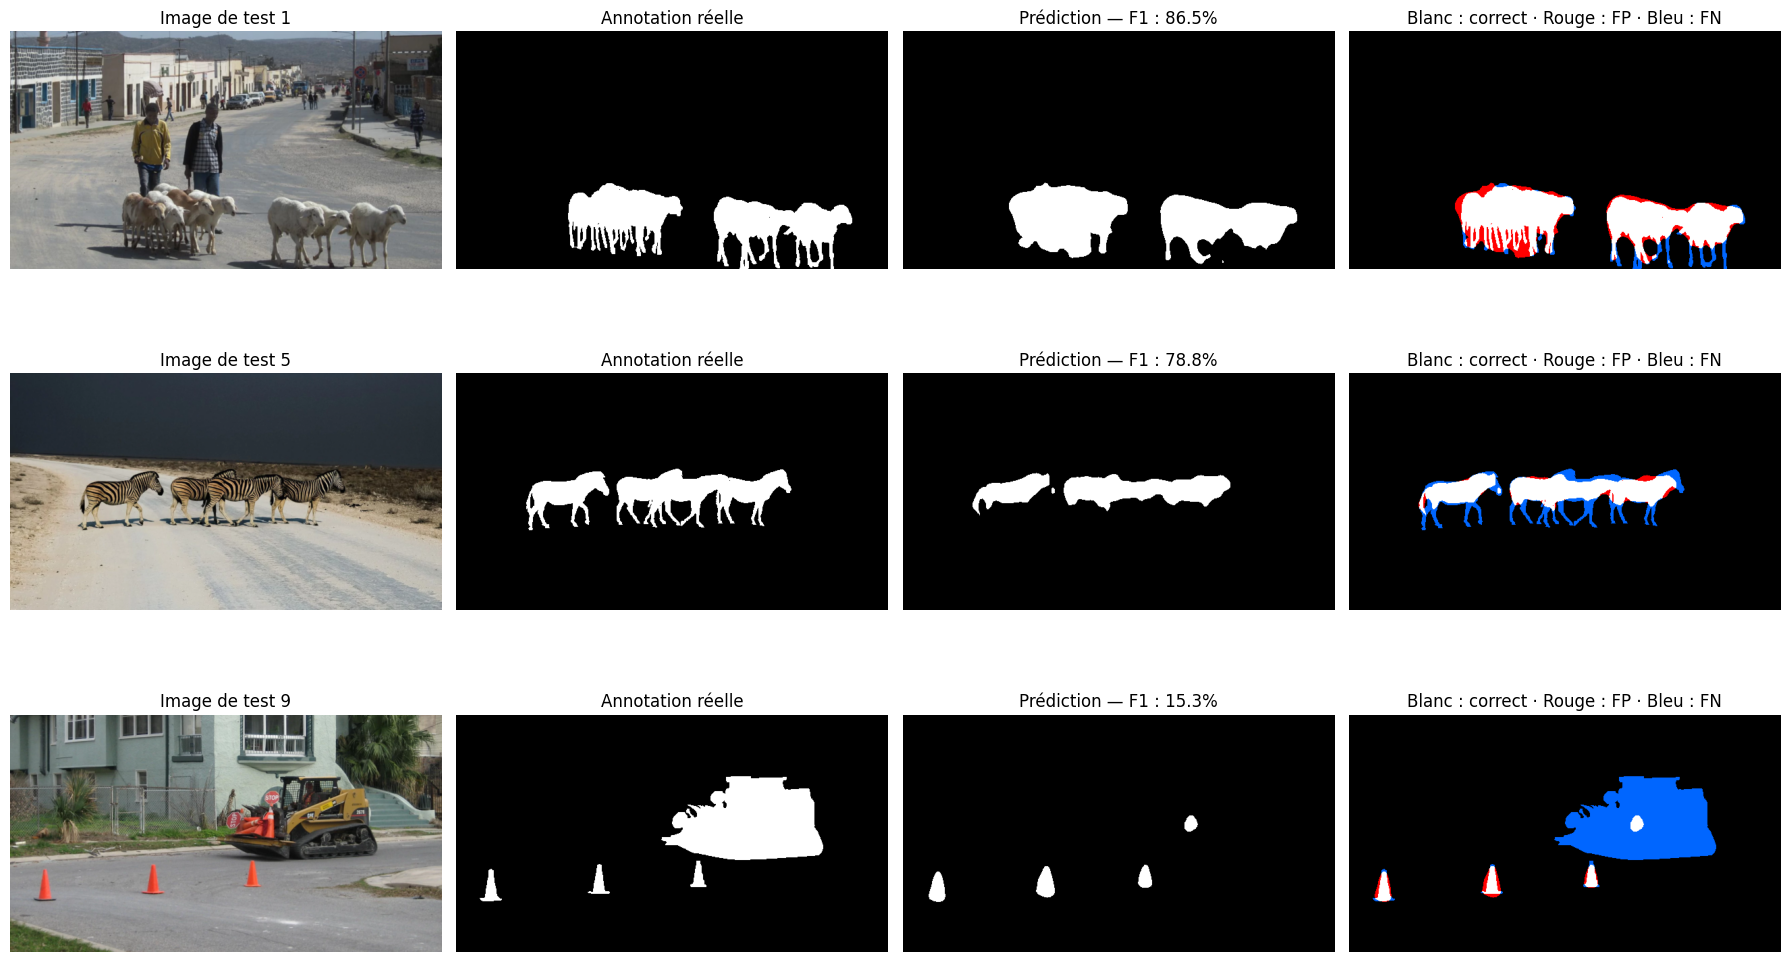

Figure sauvegardée : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0\test_examples_errors.png
FP = fausse alerte ; FN = anomalie manquée.


In [10]:
# Trois exemples fixes du test, sans les choisir selon leurs scores.
indices = [0, len(x_test) // 2, len(x_test) - 1]

fig, axes = plt.subplots(3, 4, figsize=(18, 11))

for row, index in enumerate(indices):
    actual = gt_test[index]
    predicted = pred_test[index].astype(bool)

    # Blanc : anomalie correctement détectée.
    # Rouge : fausse alerte.
    # Bleu : anomalie manquée.
    errors = np.zeros((*actual.shape, 3), dtype=np.float32)
    errors[actual & predicted] = [1, 1, 1]
    errors[~actual & predicted] = [1, 0, 0]
    errors[actual & ~predicted] = [0, 0.4, 1]

    image_f1 = test_report["per_image"][index]["f1"]

    axes[row, 0].imshow(x_test[index])
    axes[row, 0].set_title(f"Image de test {index + 1}")

    axes[row, 1].imshow(
        actual, cmap="gray", vmin=0, vmax=1
    )
    axes[row, 1].set_title("Annotation réelle")

    axes[row, 2].imshow(
        predicted, cmap="gray", vmin=0, vmax=1
    )
    axes[row, 2].set_title(f"Prédiction — F1 : {image_f1:.1%}")

    axes[row, 3].imshow(errors)
    axes[row, 3].set_title("Blanc : correct · Rouge : FP · Bleu : FN")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()

figure_path = RUN_DIR / "test_examples_errors.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)
print("FP = fausse alerte ; FN = anomalie manquée.")

## 10. Seg-Grad-CAM : comparaison ASPP et décodeur

L’explication porte sur le **logit moyen d’anomalie dans une région prédite fixée avant le calcul des gradients**, pour la première image de test. Le logit est utilisé avant sigmoid pour limiter les effets de saturation. Les cartes montrent uniquement les contributions positives après ReLU.

La comparaison couvre `decoder_2`, `aspp_1x1` et les dilatations 6, 12 et 18. Chaque carte est normalisée par son propre maximum positif : les couleurs ne mesurent pas une importance absolue comparable entre couches. Une carte nulle est signalée. La branche de pooling global n’est pas présentée comme une localisation spatiale détaillée ; le chemin de bas niveau du décodeur fournit aussi de l’information en dehors de l’ASPP.

Ces attributions décrivent le comportement du modèle sur cet exemple, sans constituer une preuve causale ni une mesure de sélection du modèle.


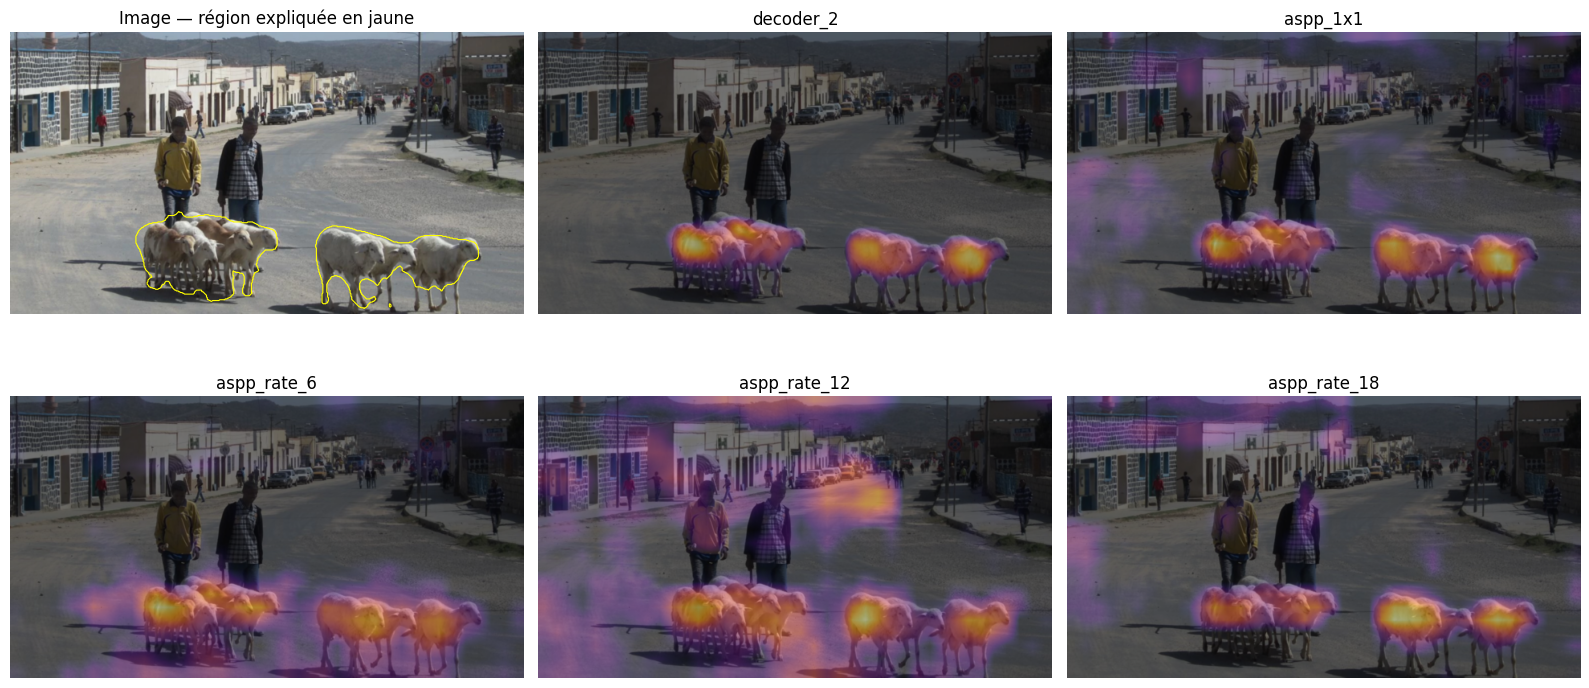

Comparaison XAI sauvegardée.


In [11]:
def binary_seg_gradcam(model, image, region, layer_name):
    """Attribution positive du logit d'anomalie dans une région fixe."""
    image = tf.convert_to_tensor(image[None], dtype=tf.float32)
    region = tf.convert_to_tensor(region, dtype=tf.float32)

    tf.debugging.assert_equal(
        tf.shape(region), tf.shape(image)[1:3]
    )
    tf.debugging.assert_positive(tf.reduce_sum(region))

    inspector = keras.Model(
        model.inputs,
        [
            model.get_layer(layer_name).output,
            model.get_layer("anomaly_logits").output,
        ],
    )

    with tf.GradientTape() as tape:
        tape.watch(image)
        features, logits = inspector(image, training=False)

        # Expliquer les logits évite la saturation de la sigmoid.
        target = (
            tf.reduce_sum(logits[0, ..., 0] * region)
            / tf.reduce_sum(region)
        )

    gradients = tape.gradient(target, features)

    if gradients is None:
        raise RuntimeError(
            f"Aucun gradient disponible pour {layer_name}."
        )

    tf.debugging.assert_all_finite(
        gradients, "Gradients non finis."
    )

    weights = tf.reduce_mean(
        gradients, axis=(1, 2), keepdims=True
    )
    heatmap = tf.nn.relu(
        tf.reduce_sum(features * weights, axis=-1)
    )

    heatmap = tf.image.resize(
        heatmap[..., None],
        tf.shape(image)[1:3],
        method="bilinear",
    )[0, ..., 0]

    raw_max = float(tf.reduce_max(heatmap).numpy())
    heatmap = tf.math.divide_no_nan(
        heatmap, tf.reduce_max(heatmap)
    )

    return heatmap.numpy(), raw_max


# Premier exemple fixe du test.
XAI_INDEX = 0
region = pred_test[XAI_INDEX].astype(bool)

if not region.any():
    raise ValueError(
        "Aucune anomalie prédite sur cet exemple : région XAI vide."
    )

layer_names = [
    "decoder_2",
    "aspp_1x1",
    "aspp_rate_6",
    "aspp_rate_12",
    "aspp_rate_18",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

axes[0, 0].imshow(x_test[XAI_INDEX])
axes[0, 0].contour(
    region.astype(float),
    levels=[0.5],
    colors="yellow",
    linewidths=0.8,
)
axes[0, 0].set_title("Image — région expliquée en jaune")

xai_metadata = []

for ax, layer_name in zip(axes.flat[1:], layer_names):
    heatmap, raw_max = binary_seg_gradcam(
        test_model,
        x_test[XAI_INDEX],
        region,
        layer_name,
    )

    ax.imshow(x_test[XAI_INDEX])
    ax.imshow(
        heatmap, cmap="inferno", alpha=0.5, vmin=0, vmax=1
    )
    ax.set_title(
        layer_name + (" — carte nulle" if raw_max == 0 else "")
    )

    np.save(
        RUN_DIR / f"xai_test_{XAI_INDEX + 1}_{layer_name}.npy",
        heatmap,
    )
    xai_metadata.append({
        "layer": layer_name,
        "raw_positive_max": raw_max,
        "zero_heatmap": raw_max == 0,
    })

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    RUN_DIR / "xai_aspp_decoder_test_1.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

(RUN_DIR / "xai_test_1.json").write_text(
    json.dumps({
        "frame": test_frames[XAI_INDEX],
        "checkpoint_sha256": checkpoint_hash,
        "target": "mean anomaly logit in fixed predicted region",
        "region_pixels": int(region.sum()),
        "normalization": "per-layer positive maximum",
        "layers": xai_metadata,
    }, indent=2),
    encoding="utf-8",
)

print("Comparaison XAI sauvegardée.")

## 11. Courbes d’apprentissage

Les deux panneaux représentent les mêmes pertes ; l’échelle logarithmique rend les petites variations plus visibles. La validation s’améliore fortement jusqu’aux époques 7–8 puis fluctue, tandis que la perte d’entraînement reste plus faible. La sélection à l’époque 8 et l’arrêt à l’époque 13 limitent la poursuite de l’apprentissage sans amélioration mesurée. Aucun second réglage n’a été retenu sur la base du test.


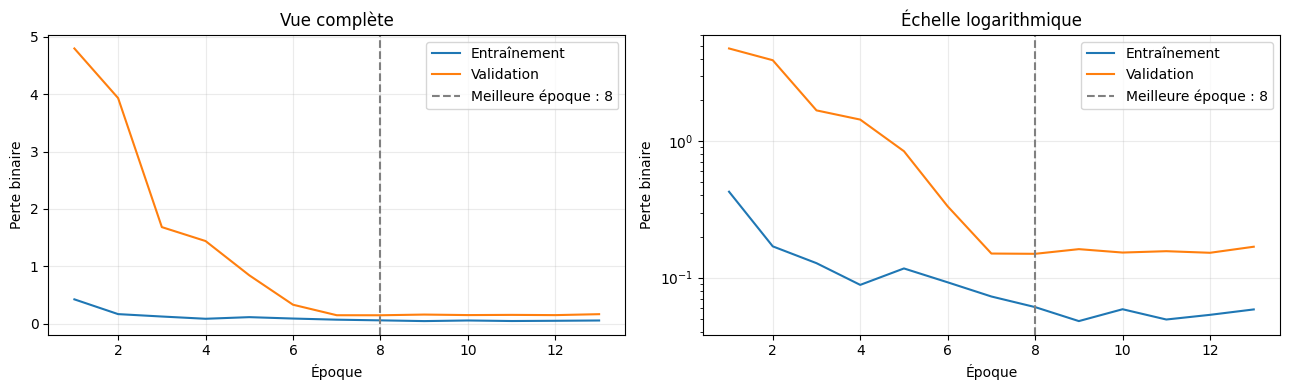

Courbes sauvegardées dans : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0


In [12]:
# Courbes issues du journal sauvegardé de cette expérience.
run_history = bilan["history"]
epochs = np.arange(1, len(run_history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax in axes:
    ax.plot(epochs, run_history["loss"], label="Entraînement")
    ax.plot(epochs, run_history["val_loss"], label="Validation")
    ax.axvline(
        bilan["best_epoch"],
        color="gray",
        linestyle="--",
        label=f"Meilleure époque : {bilan['best_epoch']}",
    )
    ax.set_xlabel("Époque")
    ax.set_ylabel("Perte binaire")
    ax.legend()
    ax.grid(alpha=0.25)

axes[0].set_title("Vue complète")
axes[1].set_yscale("log")
axes[1].set_title("Échelle logarithmique")

plt.tight_layout()
plt.savefig(
    RUN_DIR / "learning_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print("Courbes sauvegardées dans :", RUN_DIR)

## 12. Détection des obstacles par composantes

Les fonctions communes évaluent les composantes de quatre pixels ou plus. Un objet annoté est repéré si au moins 50 % de ses pixels sont prédits anormaux. Une composante prédite est une fausse alerte si moins de 50 % de ses pixels recouvrent l’annotation.

| Mesure | Moyenne par image | Intervalle bootstrap à 95 % |
|---|---:|---:|
| Précision objet | 66,39 % | 43,24–87,96 % |
| Rappel objet | 89,81 % | 72,22–100,00 % |
| F1 objet | 68,29 % | 47,65–86,95 % |

Le rappel élevé suggère que de nombreux obstacles sont partiellement couverts, avec des fausses alertes restantes. Il s’agit de moyennes par image, pas de ratios sur tous les objets regroupés. Il n’y a pas d’appariement un-à-un : une prédiction peut fusionner plusieurs animaux et rester favorablement évaluée. Ces métriques ne remplacent donc pas l’analyse des contours et de la séparation des objets.


In [13]:
# Évaluation des obstacles avec les fonctions communes de l'équipe.
# Aucun changement du modèle ou du seuil après consultation du test.

object_results = [
    metrics.object_scores(
        actual,
        predicted,
        min_size=test_min_pixels,
        overlap=0.5,
    )
    for actual, predicted in zip(gt_test, pred_test)
]

object_summary = {}

print("TEST — détection des obstacles, moyenne par image")

for name in ["object_precision", "object_recall", "object_f1"]:
    values = [result[name] for result in object_results]
    mean, low, high = metrics.bootstrap_ci(values)

    object_summary[name] = {
        "mean": float(mean),
        "low": float(low),
        "high": float(high),
    }

    print(f"{name} : {mean:.2%} [{low:.2%} ; {high:.2%}]")

object_record = {
    "frames": list(test_frames),
    "checkpoint_sha256": checkpoint_hash,
    "threshold": test_threshold,
    "min_component_pixels": test_min_pixels,
    "overlap": 0.5,
    "definition": (
        "GT object detected when at least 50% of its pixels "
        "are predicted as anomaly; precision uses predicted-component "
        "purity. No one-to-one object matching."
    ),
    "per_image": object_results,
    "per_image_mean_bootstrap_95_ci": object_summary,
}

object_path = RUN_DIR / "test_object_metrics.json"
object_path.write_text(
    json.dumps(object_record, indent=2),
    encoding="utf-8",
)

print("\nRésultats sauvegardés :", object_path)

TEST — détection des obstacles, moyenne par image
object_precision : 66.39% [43.24% ; 87.96%]
object_recall : 89.81% [72.22% ; 100.00%]
object_f1 : 68.29% [47.65% ; 86.95%]

Résultats sauvegardés : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0\test_object_metrics.json


## 13. Seg-Grad-CAM sur un exemple difficile

La neuvième image, dont le F1 est faible (environ 15,3 %), est utilisée pour une analyse descriptive après évaluation. La région cible est constituée des pixels annotés anormaux mais manqués par la prédiction, maintenue fixe pendant la différentiation. Elle est affichée en cyan.

Cette région est issue de l’annotation, contrairement à la région prédite utilisée dans la section 10 : les deux analyses ne visent pas exactement la même cible. Des contributions positives peuvent apparaître hors de la région cible, notamment du fait du contexte et de la construction Grad-CAM ; cela ne prouve pas pourquoi l’engin est manqué. Les cartes restent normalisées séparément et ne servent à aucun réglage du modèle.


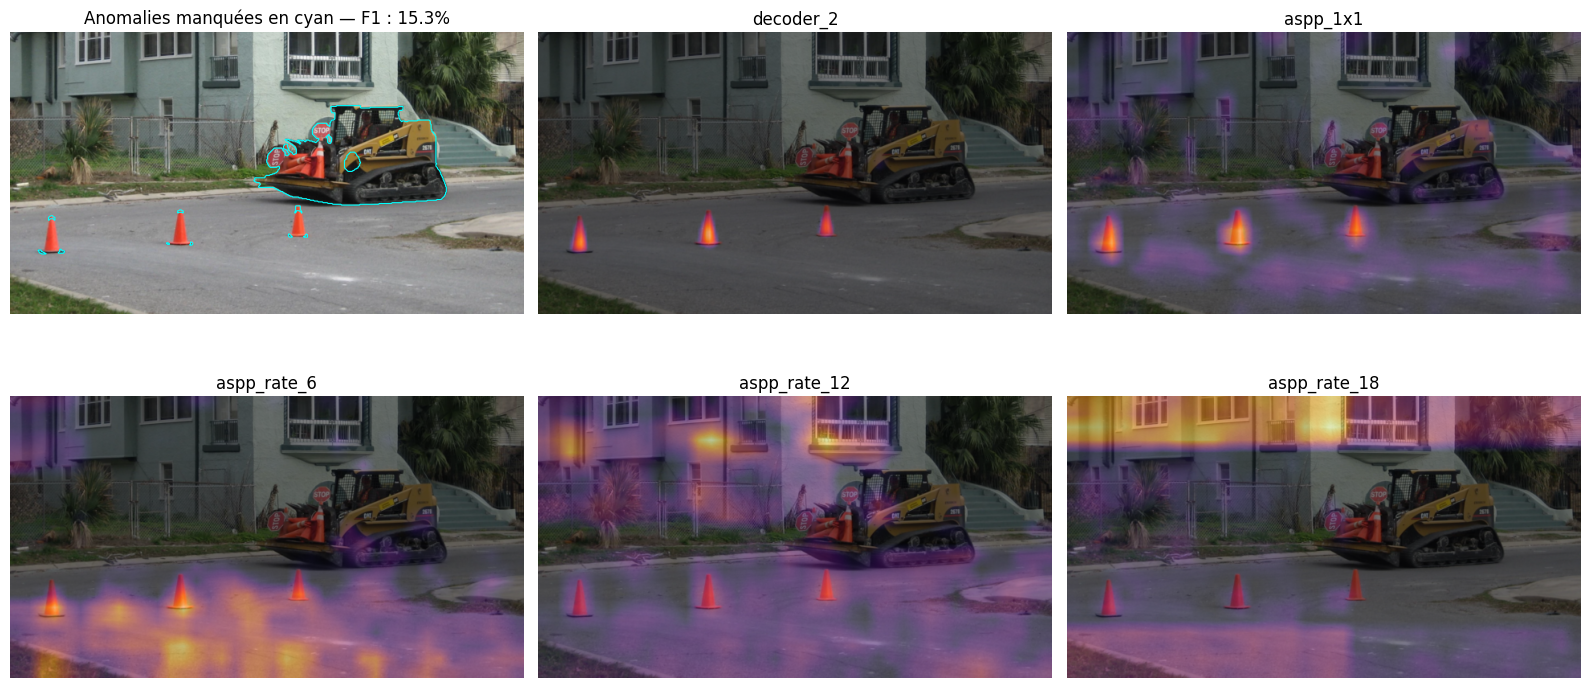

Analyse XAI de l'échec sauvegardée : c:\Users\ines trabelsi\Downloads\RoadAnomaly-CRISPDM-Ines\checkpoints\A_deeplabv3plus\20261101T012507Z-f4ec27a0\xai_failure_test_9.png


In [14]:
# Analyse XAI d'un échec : exemple de test fixé à l'indice 8.
# Analyse descriptive après évaluation, sans modifier le modèle.
FAIL_INDEX = 8

actual = gt_test[FAIL_INDEX].astype(bool)
predicted = pred_test[FAIL_INDEX].astype(bool)

# Région fixe : pixels anormaux que le modèle a manqués.
missed_region = actual & ~predicted

if not missed_region.any():
    raise ValueError("Cet exemple ne contient aucun pixel anormal manqué.")

failure_layers = [
    "decoder_2",
    "aspp_1x1",
    "aspp_rate_6",
    "aspp_rate_12",
    "aspp_rate_18",
]

image_f1 = test_report["per_image"][FAIL_INDEX]["f1"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

axes[0, 0].imshow(x_test[FAIL_INDEX])
axes[0, 0].contour(
    missed_region.astype(float),
    levels=[0.5],
    colors="cyan",
    linewidths=0.8,
)
axes[0, 0].set_title(
    f"Anomalies manquées en cyan — F1 : {image_f1:.1%}"
)

failure_metadata = []

for ax, layer_name in zip(axes.flat[1:], failure_layers):
    heatmap, raw_max = binary_seg_gradcam(
        test_model,
        x_test[FAIL_INDEX],
        missed_region,
        layer_name,
    )

    ax.imshow(x_test[FAIL_INDEX])
    ax.imshow(
        heatmap, cmap="inferno", alpha=0.5, vmin=0, vmax=1
    )
    ax.set_title(
        layer_name + (" — carte nulle" if raw_max == 0 else "")
    )

    np.save(
        RUN_DIR / f"xai_failure_test_9_{layer_name}.npy",
        heatmap,
    )

    failure_metadata.append({
        "layer": layer_name,
        "raw_positive_max": raw_max,
        "zero_heatmap": raw_max == 0,
    })

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
figure_path = RUN_DIR / "xai_failure_test_9.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

(RUN_DIR / "xai_failure_test_9.json").write_text(
    json.dumps({
        "frame": test_frames[FAIL_INDEX],
        "checkpoint_sha256": checkpoint_hash,
        "image_f1": float(image_f1),
        "analysis": "post-hoc failure analysis; no model selection",
        "target": "mean anomaly logit in fixed false-negative region",
        "region_source": "ground truth anomaly AND prediction background",
        "region_pixels": int(missed_region.sum()),
        "normalization": "per-layer positive maximum",
        "layers": failure_metadata,
    }, indent=2),
    encoding="utf-8",
)

print("Analyse XAI de l'échec sauvegardée :", figure_path)

## 14. Contrôle exploratoire par suppression et insertion

Pour la première image de test, les blocs de 32×32 pixels sont classés par la moyenne de la carte d’attribution. La région cible est le masque prédit original et ne change pas pendant le contrôle. Le score suivi est le logit moyen dans cette région.

- **Suppression :** remplacer progressivement les blocs prioritaires par une version floutée de l’image.
- **Insertion :** restaurer les blocs prioritaires depuis cette même image floutée.
- **Contrôle :** trois permutations aléatoires (graines 1337, 1338, 1339), avec six fractions de modification entre 0 et 100 %. Le flou gaussien utilise sigma = 8 pixels dans les dimensions spatiales.

Sur le graphique enregistré, l’insertion guidée par les cinq cartes remonte plus rapidement que la moyenne aléatoire aux fractions intermédiaires. En suppression, les cartes diminuent plus vite le score aux premières fractions, mais l’ordre aléatoire atteint ensuite des scores plus faibles à certaines étapes. La supériorité n’est donc pas uniforme et certaines courbes ne sont pas monotones.

Les aires sous ces courbes sont enregistrées dans le JSON ; ce sont des intégrales de logits sur la fraction modifiée, pas des pourcentages ni des AUROC. À image, cible et baseline identiques, une aire de suppression plus faible et une aire d’insertion plus élevée correspondent au comportement généralement recherché.

**Limites :** une seule image, trois contrôles aléatoires, dépendance au floutage, à la taille des blocs et aux interactions entre régions. La bande grise représente le minimum et le maximum des trois ordres aléatoires, pas un intervalle de confiance. Ces perturbations peuvent produire des entrées atypiques ; elles ne démontrent pas une causalité ou une fidélité générale sur tout le dataset.


decoder_2 : terminé
aspp_1x1 : terminé
aspp_rate_6 : terminé
aspp_rate_12 : terminé
aspp_rate_18 : terminé
Aléatoire 1 : terminé
Aléatoire 2 : terminé
Aléatoire 3 : terminé


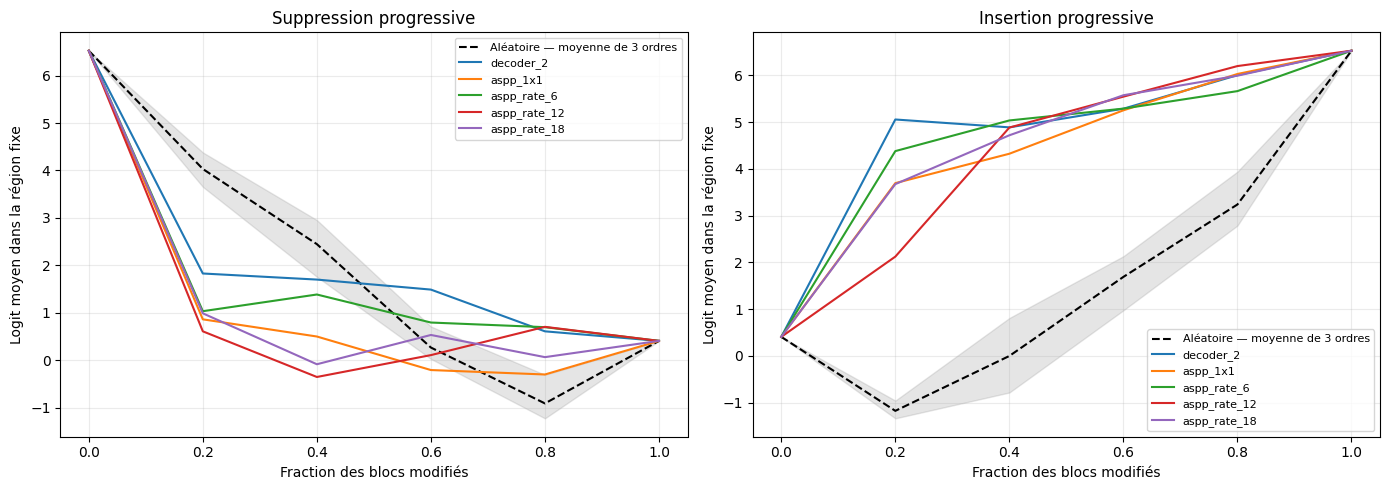

Contrôle quantitatif XAI sauvegardé.


In [15]:
from scipy.ndimage import gaussian_filter

# Contrôle exploratoire : première image de test uniquement.
CHECK_INDEX = 0
PATCH_SIZE = 32
fractions = np.linspace(0, 1, 6)

image = x_test[CHECK_INDEX].astype(np.float32)
fixed_region = pred_test[CHECK_INDEX].astype(bool)

assert fixed_region.any()

# Flouter uniquement les dimensions spatiales, sans mélanger les couleurs.
baseline = gaussian_filter(image, sigma=(8, 8, 0))
baseline = np.clip(baseline, 0, 1).astype(np.float32)

logit_model = keras.Model(
    test_model.inputs,
    test_model.get_layer("anomaly_logits").output,
)

height, width = image.shape[:2]
assert height % PATCH_SIZE == 0
assert width % PATCH_SIZE == 0

rows = height // PATCH_SIZE
cols = width // PATCH_SIZE
patch_count = rows * cols

def region_score(batch):
    logits = logit_model(
        tf.convert_to_tensor(batch, dtype=tf.float32),
        training=False,
    ).numpy()[..., 0]

    values = logits[:, fixed_region].mean(axis=1)
    assert np.isfinite(values).all()
    return values

def perturbation_curves(order):
    deletion, insertion = [], []

    for fraction in fractions:
        selected = np.zeros(patch_count, dtype=bool)
        selected[order[:int(round(fraction * patch_count))]] = True

        selected = selected.reshape(rows, cols)
        selected = np.repeat(selected, PATCH_SIZE, axis=0)
        selected = np.repeat(selected, PATCH_SIZE, axis=1)[..., None]

        deleted = np.where(selected, baseline, image)
        inserted = np.where(selected, image, baseline)

        scores = region_score(np.stack([deleted, inserted]))
        deletion.append(float(scores[0]))
        insertion.append(float(scores[1]))

    return {"deletion": deletion, "insertion": insertion}

def curve_auc(values):
    values = np.asarray(values)
    return float(np.sum(
        np.diff(fractions) * (values[:-1] + values[1:]) / 2
    ))

results = {}

for layer_name in [
    "decoder_2",
    "aspp_1x1",
    "aspp_rate_6",
    "aspp_rate_12",
    "aspp_rate_18",
]:
    heatmap = np.load(
        RUN_DIR / f"xai_test_1_{layer_name}.npy"
    )

    # Une carte nulle ne définit pas de classement pertinent.
    if not np.any(heatmap > 0):
        print(layer_name, ": carte nulle, contrôle ignoré.")
        continue

    patch_scores = heatmap.reshape(
        rows, PATCH_SIZE, cols, PATCH_SIZE
    ).mean(axis=(1, 3))

    order = np.argsort(
        -patch_scores.ravel(), kind="stable"
    )
    results[layer_name] = perturbation_curves(order)
    print(layer_name, ": terminé", flush=True)

for index in range(3):
    rng = np.random.default_rng(SEED + index)
    results[f"random_{index + 1}"] = perturbation_curves(
        rng.permutation(patch_count)
    )
    print(f"Aléatoire {index + 1} : terminé", flush=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, kind, title in zip(
    axes,
    ["deletion", "insertion"],
    ["Suppression progressive", "Insertion progressive"],
):
    random_curves = np.array([
        results[f"random_{index + 1}"][kind]
        for index in range(3)
    ])

    ax.plot(
        fractions,
        random_curves.mean(axis=0),
        "k--",
        label="Aléatoire — moyenne de 3 ordres",
    )
    ax.fill_between(
        fractions,
        random_curves.min(axis=0),
        random_curves.max(axis=0),
        color="gray",
        alpha=0.2,
    )

    for name, curves in results.items():
        if not name.startswith("random_"):
            ax.plot(fractions, curves[kind], label=name)

    ax.set_title(title)
    ax.set_xlabel("Fraction des blocs modifiés")
    ax.set_ylabel("Logit moyen dans la région fixe")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(
    RUN_DIR / "xai_perturbation_test_1.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

for curves in results.values():
    curves["deletion_auc"] = curve_auc(curves["deletion"])
    curves["insertion_auc"] = curve_auc(curves["insertion"])

(RUN_DIR / "xai_perturbation_test_1.json").write_text(
    json.dumps({
        "frame": test_frames[CHECK_INDEX],
        "checkpoint_sha256": checkpoint_hash,
        "target": "mean anomaly logit in fixed predicted region",
        "region_pixels": int(fixed_region.sum()),
        "patch_size": PATCH_SIZE,
        "baseline": "Gaussian blur, spatial sigma=8 pixels",
        "fractions": fractions.tolist(),
        "random_seeds": [SEED + index for index in range(3)],
        "scope": "exploratory single-image perturbation check",
        "results": results,
    }, indent=2),
    encoding="utf-8",
)

print("Contrôle quantitatif XAI sauvegardé.")

## 15. Bilan, limites et utilisation des résultats

Cette première expérience fournit un pipeline de segmentation supervisée exécuté de bout en bout : encodeur ImageNet gelé, entraînement du module ASPP et du décodeur, checkpoint choisi sur validation, seuil fixé avant le test, métriques pixels et objets, visualisation des erreurs et analyse XAI.

Le F1 pixel moyen de **70,51 %** et l’IoU anomalie de **58,04 %** constituent une référence exploitable pour la comparaison des approches de l’équipe. Le rappel objet élevé ne garantit ni des contours précis ni l’absence de fausses alertes. La variabilité entre images et les intervalles larges doivent accompagner toute présentation des scores.

La comparaison avec les autres modèles exige le même manifeste, les mêmes conventions de masques et de post-traitement, et des réglages effectués sur validation uniquement. La segmentation supervisée et un autoencodeur apprenant sur des données normales ont des hypothèses différentes, à expliciter dans la comparaison. Aucun résultat de fine-tuning de l’encodeur, Boundary IoU ou mIoU binaire n’est revendiqué ici ; ces compléments éventuels restent à coordonner avec le binôme.

### Fichiers et intégration

Les résultats de cette expérience sont enregistrés dans :

`checkpoints/A_deeplabv3plus/20261101T012507Z-f4ec27a0/`

Ce dossier contient notamment `best.keras`, `run.json`, `history.csv`, `validation_metrics.json`, `test_metrics.json`, `test_predictions.npz`, `test_object_metrics.json`, les figures et les fichiers XAI. Les sorties du notebook attestent les opérations effectuées sur le poste d’Inès ; ces fichiers externes ne sont pas inclus dans le notebook transmis.

Pour l’inférence, charger le modèle Keras et **le seuil exact du JSON de validation**, fournir une image RGB float32 dans `[0, 1]` à la résolution 352×640, puis appliquer le filtrage prévu de quatre pixels. Le prétraitement spécifique ResNet50 est déjà intégré au modèle. Une image redimensionnée directement peut être déformée ; cette convention doit rester la même lors de la comparaison.

L’intégration dans une interface ou une API et la vérification sur un autre poste restent à réaliser. La disponibilité du checkpoint et de ses paramètres de post-traitement est nécessaire : le notebook seul ne permet pas une démonstration d’inférence autonome. Les nouvelles études d’amélioration devront être planifiées sur entraînement/validation, avec une évaluation finale réellement indépendante si l’objectif est de mesurer la généralisation.
